In [25]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Diretório dos arquivos
pasta = Path(r"C:\Users\Nicho\Downloads\Base_de_dados")

# 2. Ler Selic Diária
df_selic = pd.read_csv(
    pasta / "Selic_Diaria_2002_2026.csv",
    sep=";",
    decimal=",",
    encoding="latin1",
)
col_s_date, col_s_val = df_selic.columns[0], df_selic.columns[1]

df_selic["data"] = pd.to_datetime(
    df_selic[col_s_date], format="%d/%m/%Y", errors="coerce"
)
df_selic["selic"] = pd.to_numeric(
    df_selic[col_s_val].astype(str).str.replace(",", "."), errors="coerce"
)
df_selic = df_selic.dropna(subset=["data"])

# Média mensal da Selic (compatível com Pandas 2.2+ e versões anteriores)
try:
    selic_mensal = df_selic.set_index("data")["selic"].resample("ME").mean()
except ValueError:
    selic_mensal = df_selic.set_index("data")["selic"].resample("M").mean()


# 3. Ler Base Mensal (Godley + Macro)
df_macro = pd.read_csv(
    pasta / "Godley_Macro_2002_2026_Mensal.csv",
    sep=";",
    decimal=",",
    encoding="latin1",
)

novas_cols = {}
for col in df_macro.columns:
    c = col.strip()
    if c.lower() == "data":
        novas_cols[col] = "data"
    elif "433" in c:
        novas_cols[col] = "ipca"
    elif "4505" in c:
        novas_cols[col] = "dlsp_4505"
    elif "4513" in c:
        novas_cols[col] = "dlsp_pib"
    elif "4945" in c:
        novas_cols[col] = "nfsp_operacional"
    elif "13762" in c:
        novas_cols[col] = "dbgg_pib"

df_macro = df_macro.rename(columns=novas_cols)

# Data mensal no formato MM/YYYY
df_macro["data"] = pd.to_datetime(
    df_macro["data"], format="%m/%Y", errors="coerce"
)
df_macro = df_macro.dropna(subset=["data"]).set_index("data").sort_index()

# Conversão numérica explícita
for col in df_macro.columns:
    df_macro[col] = pd.to_numeric(
        df_macro[col].astype(str).str.replace(",", "."), errors="coerce"
    )

# Alinhar ao último dia do mês para cruzar com a Selic
df_macro.index = df_macro.index + pd.offsets.MonthEnd(0)
df_macro["selic_meta"] = selic_mensal
df_macro = df_macro.interpolate(method="time").bfill()

# 4. Cálculo de IPCA 12M e Juro Real Ex-Post
df_macro["ipca_12m"] = (
    (1 + df_macro["ipca"] / 100).rolling(12).apply(np.prod, raw=True) - 1
) * 100
df_macro["juro_real"] = (
    (1 + df_macro["selic_meta"] / 100) / (1 + df_macro["ipca_12m"] / 100) - 1
) * 100

print("🚀 Base carregada e sincronizada com sucesso!")
print(df_macro[["selic_meta", "ipca_12m", "juro_real", "dbgg_pib"]].tail())

🚀 Base carregada e sincronizada com sucesso!
            selic_meta  ipca_12m  juro_real  dbgg_pib
data                                                 
2026-04-30   14.741667  4.391720   9.914529     80.10
2026-05-31   14.500000  4.724907   9.334067     81.04
2026-06-30   14.391667  4.641328   9.317866     81.95
2026-07-31   14.250000  4.443025   9.389785     82.56
2026-08-31   14.040323  4.223453   9.419060     82.86


In [27]:
## Matriz Stock-Flow Consistent

# 1. Média recente dos dados para compor os fluxos (% do PIB aproximado)
ultimos_dados = df_macro.tail(12).mean()

selic = ultimos_dados["selic_meta"]
ipca = ultimos_dados["ipca_12m"]
juro_real = ultimos_dados["juro_real"]
dbgg = ultimos_dados["dbgg_pib"]
dlsp = ultimos_dados["dlsp_pib"]

# Encargo nominal aproximado da dívida (% PIB)
conta_juros = dbgg * (selic / 100)
resultado_operacional = ultimos_dados.get("nfsp_operacional", 0.5)

# --- MATRIZ DE BALANÇOS (STOCKS) ---
estoques_data = {
    "Setor Privado": [dlsp, "DBGG - DLSP", "V_p (Riqueza Privada)"],
    "Setor Público": [-dlsp, "-DBGG", "-V_g (Passivo Líquido)"],
    "Setor Externo / Ativos Líquidos": [0, "DBGG - DLSP", "V_e"],
    "TOTAL": [0, 0, 0]
}

# Criando dataframe estilizado para o Balanço Patrimonial
df_stocks = pd.DataFrame({
    "Setor Privado (Famílias/Firmas)": [f"+{dlsp:.1f}%", f"+{(dbgg-dlsp):.1f}%", f"+{dbgg:.1f}%"],
    "Setor Público (Governo)": [f"-{dlsp:.1f}%", f"-{dbgg:.1f}%", f"-{dlsp:.1f}%"],
    "Total da Economia": ["0.0%", "0.0%", "0.0%"]
}, index=["Títulos Públicos Líquidos (DLSP)", "Ajuste Patrimonial/Ativos Brutos", "Posição Financeira Líquida"])

# --- MATRIZ DE FLUXOS DE TRANSAÇÃO (FLOWS) ---
# Convenção: (+) Entrada de caixa | (-) Saída de caixa
df_flows = pd.DataFrame({
    "Setor Privado": ["- Consumo/Investimento", "+ Gastos Públicos (G)", "- Impostos (T)", f"+{conta_juros:.2f}% (Juros Rec.)", f"\\Delta V_p"],
    "Governo Central": ["+ Consumo/Investimento", "- Gastos Públicos (G)", "+ Impostos (T)", f"-{conta_juros:.2f}% (Juros Pagos)", f"\\Delta D_g"],
    "Soma das Linhas (Identidade)": ["0", "0", "0", "0", "0"]
}, index=["Consumo/Investimento (C+I)", "Compras do Governo (G)", "Impostos Líquidos (T)", "Serviço da Dívida (Juros)", "Acumulação Financeira Líquida"])

print("=========================================================")
print("1. MATRIZ DE BALANÇOS PATRIMONIAIS (% PIB - Média Recente)")
print("=========================================================")
display(df_stocks)

print("\n=========================================================")
print("2. MATRIZ DE FLUXOS DE TRANSAÇÃO (Estrutura de Godley)")
print("=========================================================")
display(df_flows)

1. MATRIZ DE BALANÇOS PATRIMONIAIS (% PIB - Média Recente)


,Setor Privado (Famílias/Firmas),Setor Público (Governo),Total da Economia
Títulos Públicos Líquidos (DLSP),+66.6%,-66.6%,0.0%
Ajuste Patrimonial/Ativos Brutos,+13.4%,-80.0%,0.0%
Posição Financeira Líquida,+80.0%,-66.6%,0.0%



2. MATRIZ DE FLUXOS DE TRANSAÇÃO (Estrutura de Godley)


,Setor Privado,Governo Central,Soma das Linhas (Identidade)
Consumo/Investimento (C+I),- Consumo/Investimento,+ Consumo/Investimento,0
Compras do Governo (G),+ Gastos Públicos (G),- Gastos Públicos (G),0
Impostos Líquidos (T),- Impostos (T),+ Impostos (T),0
Serviço da Dívida (Juros),+11.79% (Juros Rec.),-11.79% (Juros Pagos),0
Acumulação Financeira Líquida,\Delta V_p,\Delta D_g,0


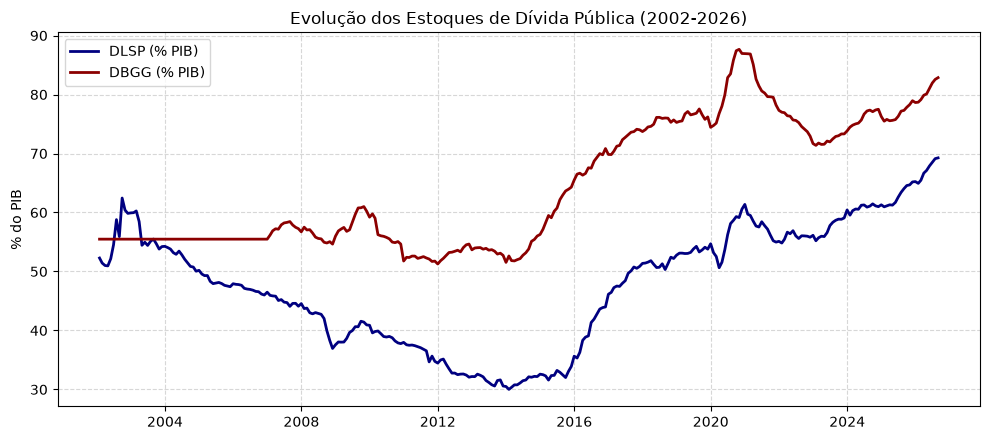

In [28]:
## Ajuste Stock-Flow

# Cálculo da variação mensal da DLSP em p.p. do PIB
df_macro["delta_dlsp"] = df_macro["dlsp_pib"].diff()

# Variação acumulada em 12 meses
df_macro["delta_dlsp_12m"] = df_macro["dlsp_pib"].diff(12)

# Exibir gráfico de consistência Stock-Flow
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4.5))
plt.plot(df_macro.index, df_macro["dlsp_pib"], label="DLSP (% PIB)", color="navy", linewidth=2)
plt.plot(df_macro.index, df_macro["dbgg_pib"], label="DBGG (% PIB)", color="darkred", linewidth=2)
plt.title("Evolução dos Estoques de Dívida Pública (2002-2026)")
plt.ylabel("% do PIB")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

 Dívida de Partida (2026): 82.86% do PIB
 Superávit Primário necessário para estabilizar a DBGG no Cenário Base (s*): 3.25% do PIB



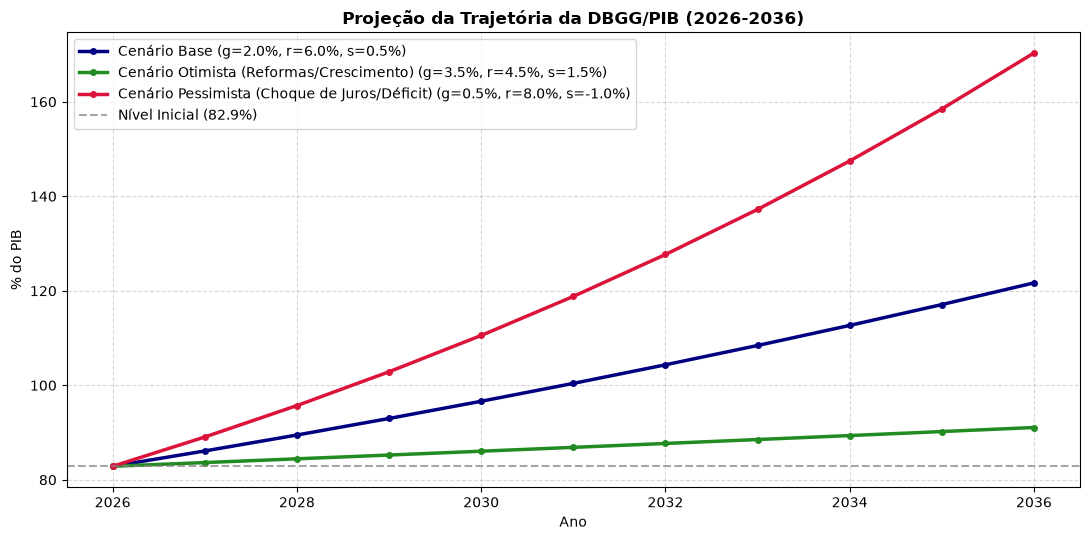

In [29]:
## Projetando dívida em vários cenários

# 1. Ponto de partida (último valor observado na base)
d0 = df_macro["dbgg_pib"].iloc[-1]
ano_inicio = df_macro.index[-1].year
anos = np.arange(ano_inicio, ano_inicio + 11)

# 2. Definição dos Cenários (PIB real 'g', Juro real 'r', Primário 's')
cenarios = {
    "Cenário Base": {"g": 0.020, "r": 0.060, "s": 0.005, "cor": "navy"},
    "Cenário Otimista (Reformas/Crescimento)": {"g": 0.035, "r": 0.045, "s": 0.015, "cor": "forestgreen"},
    "Cenário Pessimista (Choque de Juros/Déficit)": {"g": 0.005, "r": 0.080, "s": -0.010, "cor": "crimson"}
}

df_proj = pd.DataFrame(index=anos)

for nome, p in cenarios.items():
    trajetoria = [d0]
    r, g, s = p["r"], p["g"], p["s"]
    
    for t in range(1, len(anos)):
        d_ant = trajetoria[-1]
        d_prox = d_ant * ((1 + r) / (1 + g)) - s
        trajetoria.append(d_prox)
        
    df_proj[nome] = trajetoria

# 3. Cálculo do Superávit de Estabilização Atual (s*)
r_base, g_base = cenarios["Cenário Base"]["r"], cenarios["Cenário Base"]["g"]
s_star = d0 * ((r_base - g_base) / (1 + g_base))

print(f" Dívida de Partida ({ano_inicio}): {d0:.2f}% do PIB")
print(f" Superávit Primário necessário para estabilizar a DBGG no Cenário Base (s*): {s_star:.2f}% do PIB\n")

# 4. Gráfico das Trajetórias
plt.figure(figsize=(11, 5.5))

for nome, p in cenarios.items():
    plt.plot(df_proj.index, df_proj[nome], label=f"{nome} (g={p['g']*100:.1f}%, r={p['r']*100:.1f}%, s={p['s']*100:.1f}%)", 
             color=p["cor"], linewidth=2.5, marker="o", markersize=4)

plt.axhline(d0, color="gray", linestyle="--", alpha=0.7, label=f"Nível Inicial ({d0:.1f}%)")
plt.title(f"Projeção da Trajetória da DBGG/PIB ({ano_inicio}-{ano_inicio+10})", fontsize=12, fontweight="bold")
plt.xlabel("Ano")
plt.ylabel("% do PIB")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(frameon=True, loc="upper left")
plt.tight_layout()
plt.show()

In [30]:
## Testando o comportamento de reação do governo

import statsmodels.api as sm

# 1. Preparação das Variáveis com Defasagens (Lags)
df_reg = df_macro.copy()

# Defasagem de 1 mês para a Dívida e para o Resultado Fiscal (Inércia)
df_reg["dbgg_lag1"] = df_reg["dbgg_pib"].shift(1)
df_reg["dlsp_lag1"] = df_reg["dlsp_pib"].shift(1)
df_reg["nfsp_lag1"] = df_reg["nfsp_operacional"].shift(1)
df_reg["juro_real_lag1"] = df_reg["juro_real"].shift(1)

# Remover missings gerados pelas defasagens
df_clean = df_reg.dropna(subset=["nfsp_operacional", "nfsp_lag1", "dbgg_lag1", "juro_real_lag1"])

# 2. Especificação do Modelo 1: Com DBGG (Dívida Bruta)
X_dbgg = df_clean[["nfsp_lag1", "dbgg_lag1", "juro_real_lag1"]]
X_dbgg = sm.add_constant(X_dbgg)
y = df_clean["nfsp_operacional"]

# Estimativa via OLS com Erros-Padrão HAC / Newey-West (Robustos a Heterocedasticidade e Autocorrelação)
modelo_dbgg = sm.OLS(y, X_dbgg).fit(cov_type="HAC", cov_kwds={"maxlags": 4})

# 3. Especificação do Modelo 2: Com DLSP (Dívida Líquida)
X_dlsp = df_clean[["nfsp_lag1", "dlsp_lag1", "juro_real_lag1"]]
X_dlsp = sm.add_constant(X_dlsp)

modelo_dlsp = sm.OLS(y, X_dlsp).fit(cov_type="HAC", cov_kwds={"maxlags": 4})

# 4. Apresentação Sintética dos Resultados
def extrair_resumo(modelo, nome_divida):
    gamma = modelo.params[nome_divida]
    p_val = modelo.pvalues[nome_divida]
    r2 = modelo.rsquared
    return gamma, p_val, r2

g_dbgg, p_dbgg, r2_dbgg = extrair_resumo(modelo_dbgg, "dbgg_lag1")
g_dlsp, p_dlsp, r2_dlsp = extrair_resumo(modelo_dlsp, "dlsp_lag1")

print("======================================================================")
print(" RESULTADOS DA FUNÇÃO DE REAÇÃO FISCAL (BOHN, 1998)")
print("======================================================================")
print(f"\n1. ESPECIFICAÇÃO COM DÍVIDA BRUTA (DBGG):")
print(f"   - Coeficiente de Reação (gamma_DBGG): {g_dbgg:.4f}")
print(f"   - p-valor: {p_dbgg:.4f} {'(Significante a 5%)' if p_dbgg < 0.05 else '(Não significante)'}")
print(f"   - R² Ajustado: {modelo_dbgg.rsquared_adj:.4f}")

print(f"\n2. ESPECIFICAÇÃO COM DÍVIDA LÍQUIDA (DLSP):")
print(f"   - Coeficiente de Reação (gamma_DLSP): {g_dlsp:.4f}")
print(f"   - p-valor: {p_dlsp:.4f} {'(Significante a 5%)' if p_dlsp < 0.05 else '(Não significante)'}")
print(f"   - R² Ajustado: {modelo_dlsp.rsquared_adj:.4f}")

print("\n======================================================================")
print(" REGRESSÃO COMPLETA (DBGG):")
print(modelo_dbgg.summary())

 RESULTADOS DA FUNÇÃO DE REAÇÃO FISCAL (BOHN, 1998)

1. ESPECIFICAÇÃO COM DÍVIDA BRUTA (DBGG):
   - Coeficiente de Reação (gamma_DBGG): -0.2792
   - p-valor: 0.1250 (Não significante)
   - R² Ajustado: 0.9396

2. ESPECIFICAÇÃO COM DÍVIDA LÍQUIDA (DLSP):
   - Coeficiente de Reação (gamma_DLSP): 0.1140
   - p-valor: 0.4140 (Não significante)
   - R² Ajustado: 0.9393

 REGRESSÃO COMPLETA (DBGG):
                            OLS Regression Results                            
Dep. Variable:       nfsp_operacional   R-squared:                       0.940
Model:                            OLS   Adj. R-squared:                  0.940
Method:                 Least Squares   F-statistic:                     1195.
Date:                Sat, 03 Oct 2026   Prob (F-statistic):          3.28e-159
Time:                        20:07:38   Log-Likelihood:                -1429.8
No. Observations:                 284   AIC:                             2868.
Df Residuals:                     280   BIC:       

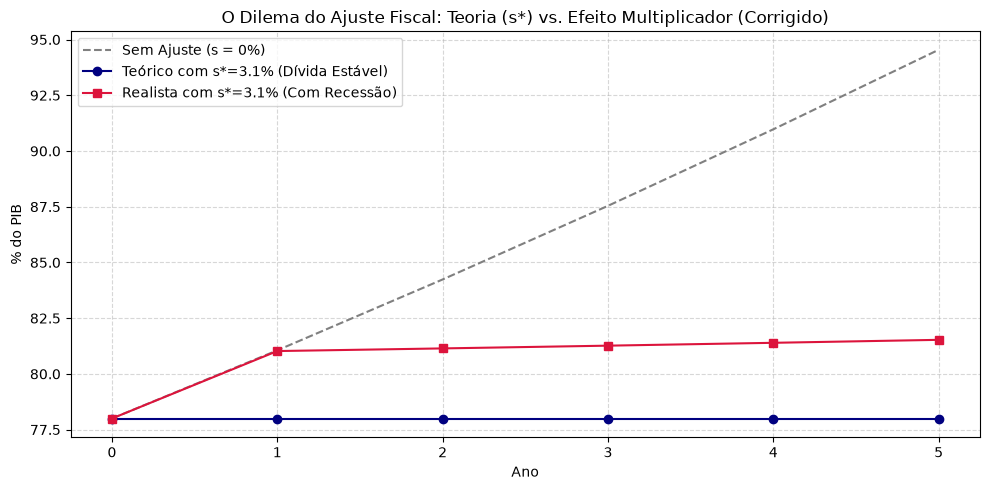

In [37]:
## Testando um modelo no qual os gastos do governo afetam o PIB

# Parâmetros
d0 = 78.0  # Dívida inicial (% PIB)
r = 0.06  # Juro real (6%)
g_potencial = 0.02  # PIB potencial (2%)
m = 1.2  # Multiplicador fiscal

# Superávit de Estabilização Teórico em decimal (~0.0306 ou 3.06% do PIB)
s_star_dec = d0 * ((r - g_potencial) / (1 + g_potencial)) / 100.0
s_star_pct = s_star_dec * 100.0

# 1. Cenário Sem Ajuste (s = 0%)
d_sem_ajuste = [d0]
for t in range(1, 6):
    d_prox = d_sem_ajuste[-1] * ((1 + r) / (1 + g_potencial))
    d_sem_ajuste.append(d_prox)

# 2. Cenário s* Teórico (Sem efeito no PIB - 'Ingênuo')
d_star_ingenuo = [d0]
for t in range(1, 6):
    d_prox = d_star_ingenuo[-1] * ((1 + r) / (1 + g_potencial)) - s_star_pct
    d_star_ingenuo.append(d_prox)

# 3. Cenário s* Realista (Com contração do PIB no Ano 1)
d_star_real = [d0]
s_ant = 0.0
for t in range(1, 6):
    s = s_star_dec
    delta_s = s - s_ant
    g_efetivo = g_potencial - (m * delta_s)

    # Multiplica 's' por 100 ao subtrair para manter a dívida em % do PIB
    d_prox = d_star_real[-1] * ((1 + r) / (1 + g_efetivo)) - (s * 100)
    d_star_real.append(d_prox)
    s_ant = s  # Após o choque inicial, delta_s volta a 0 nos anos seguintes

df_star = pd.DataFrame({
    "Ano": range(0, 6),
    "Sem Ajuste (s = 0%)": d_sem_ajuste,
    "Estabilização Teórica s* (sem impacto no PIB)": d_star_ingenuo,
    "Estabilização Real s* (com choque no PIB)": d_star_real,
})

# Plot
plt.figure(figsize=(10, 5))
plt.plot(
    df_star["Ano"],
    df_star["Sem Ajuste (s = 0%)"],
    "--",
    color="gray",
    label="Sem Ajuste (s = 0%)",
)
plt.plot(
    df_star["Ano"],
    df_star["Estabilização Teórica s* (sem impacto no PIB)"],
    "-o",
    color="navy",
    label=f"Teórico com s*={s_star_pct:.1f}% (Dívida Estável)",
)
plt.plot(
    df_star["Ano"],
    df_star["Estabilização Real s* (com choque no PIB)"],
    "-s",
    color="crimson",
    label=f"Realista com s*={s_star_pct:.1f}% (Com Recessão)",
)

plt.title(
    "O Dilema do Ajuste Fiscal: Teoria (s*) vs. Efeito Multiplicador (Corrigido)"
)
plt.xlabel("Ano")
plt.ylabel("% do PIB")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()